Break dates: ['2021-12-13', '2021-12-20', '2022-01-04', '2022-01-19']
Break indices: [12, 19, 34, 49]

Running model: constant

Running model: exp
  Optimization message: ABNORMAL_TERMINATION_IN_LNSRCH

Running model: inverse
  Optimization message: ABNORMAL_TERMINATION_IN_LNSRCH

Running model: hill
  Optimization message: ABNORMAL_TERMINATION_IN_LNSRCH

Running model: linear

Model comparison table
  model_name  success     gamma       rho             I0           MSE  \
0   constant     True  0.142857  0.911555  197113.548867  7.650354e+07   
1     linear     True  0.142857  0.999187  197113.547587  5.227312e+08   
2       hill    False  0.142857  1.233086  197113.513135  3.420948e+09   
3    inverse    False  0.142857  2.238328  197112.782069  1.203237e+11   
4        exp    False  0.142857  1.000000  197113.571429  9.676349e+09   

            RMSE    log_MSE    seg1_b    seg2_b  ...    seg1_h    seg2_h  \
0    8746.630329   0.006760  0.203075  0.211935  ...       NaN       NaN   

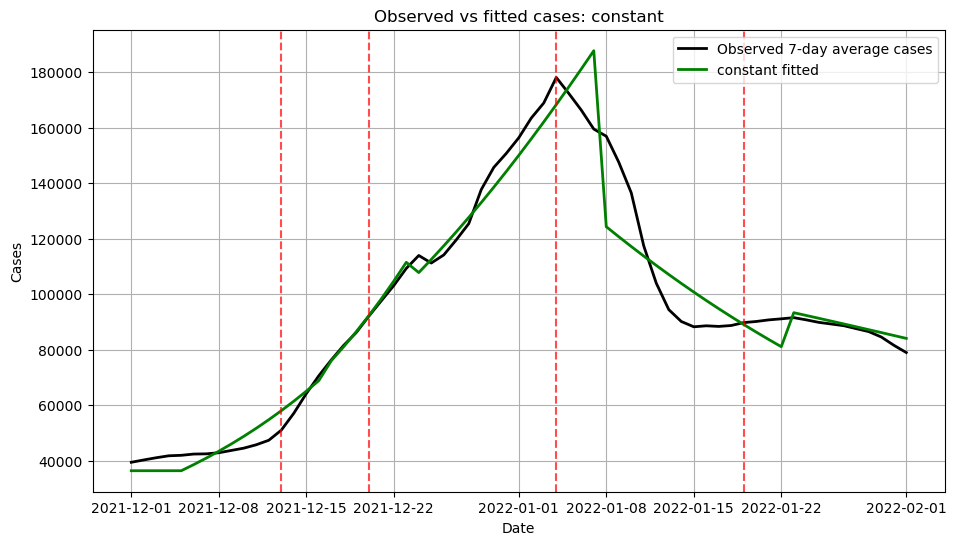

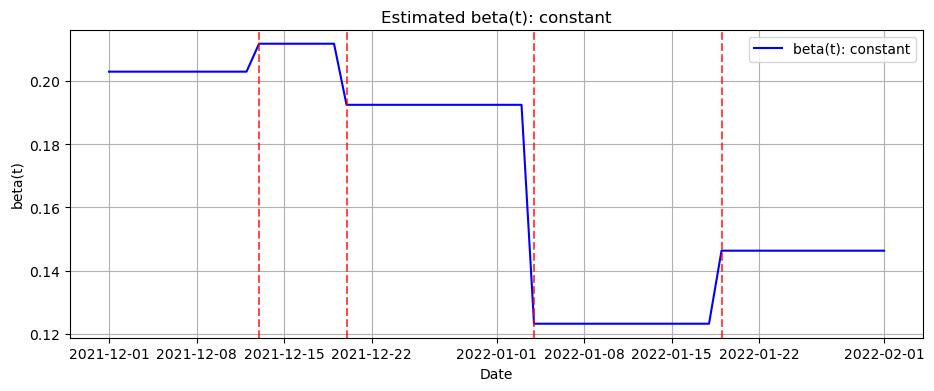

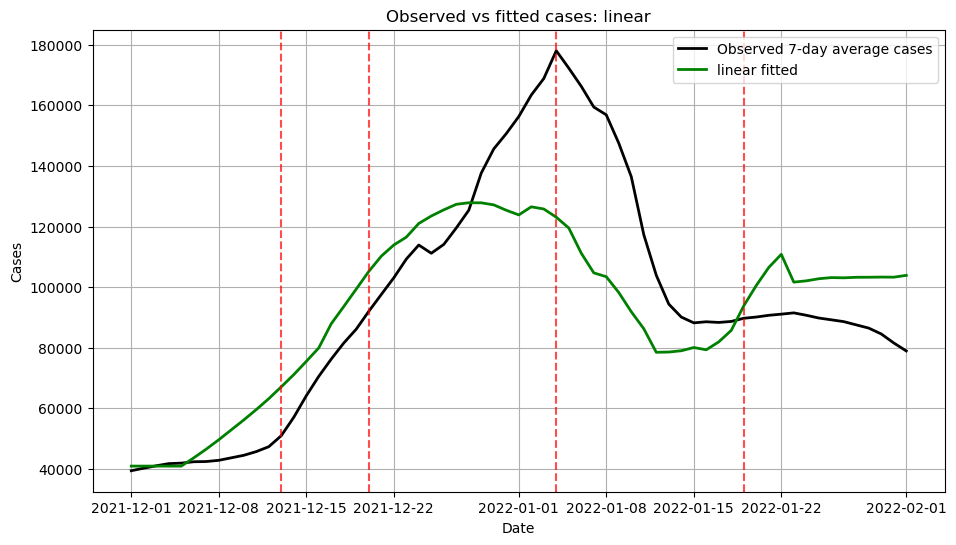

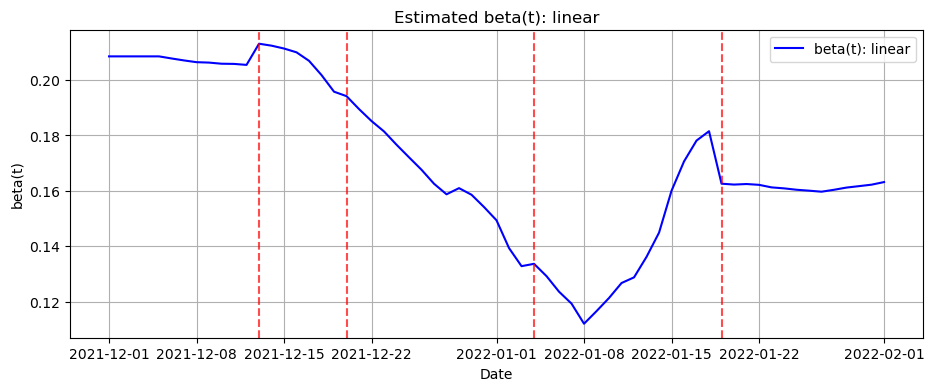

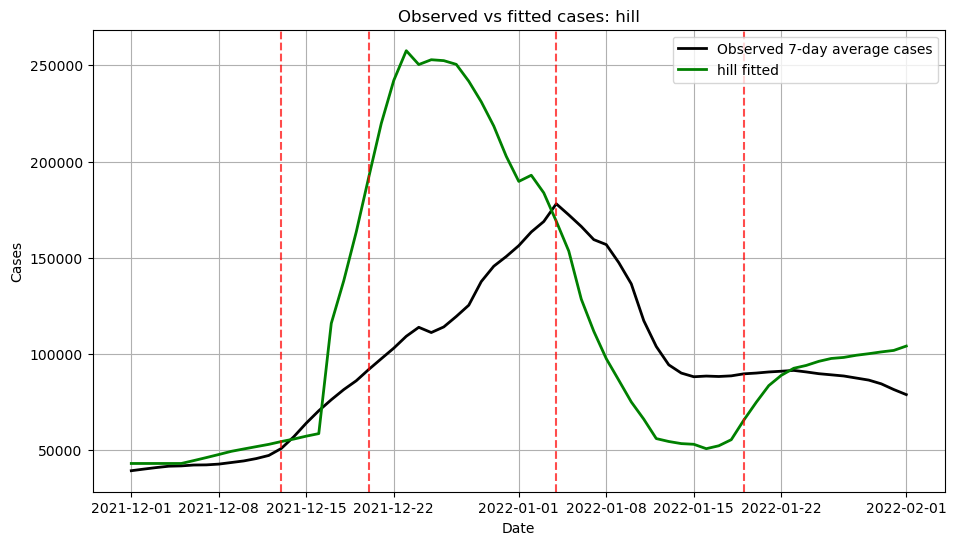

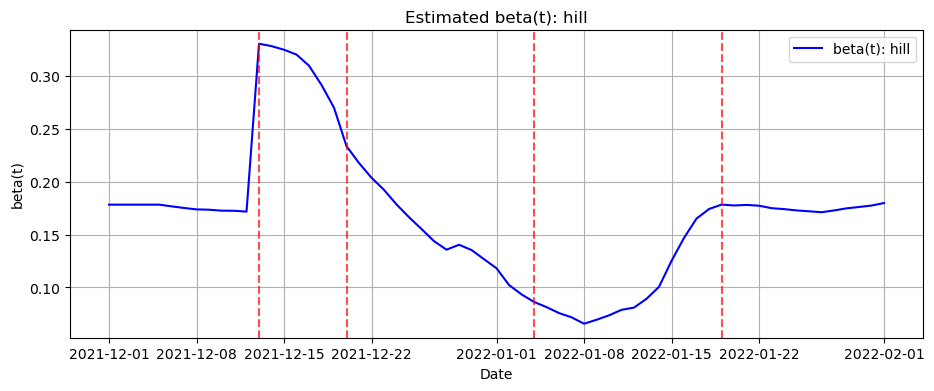

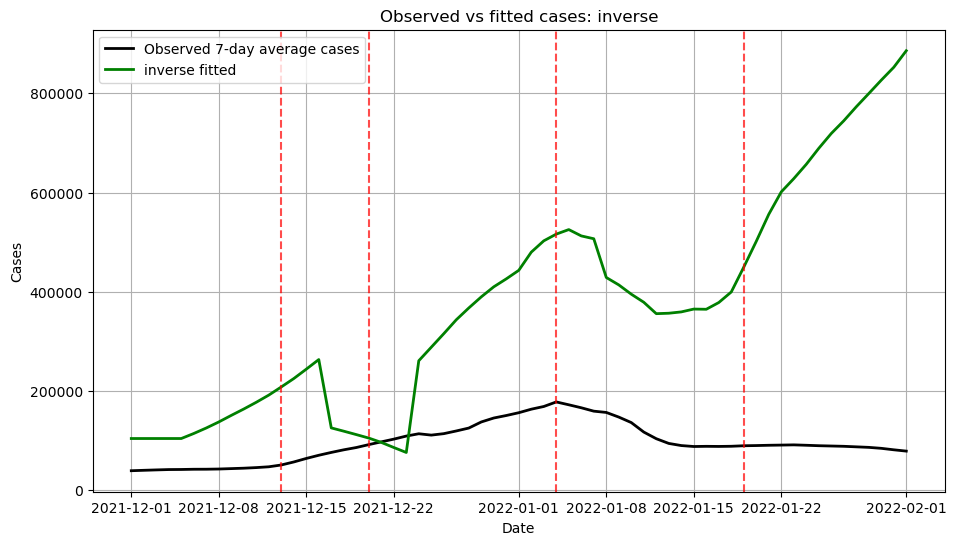

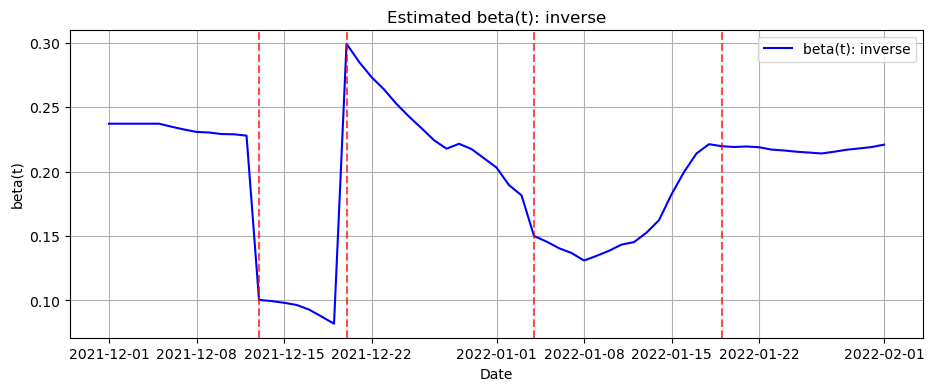

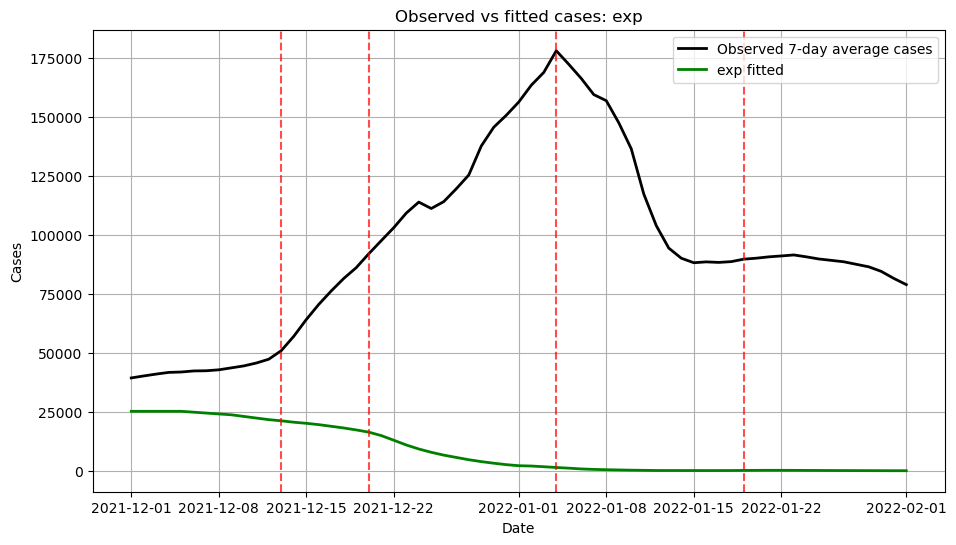

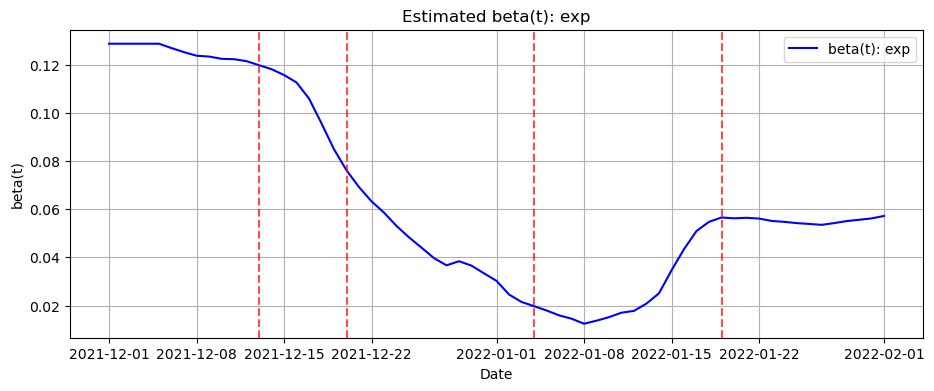


Best model: constant
Best model segment parameters:
  Segment 1: {'b': 0.20307540874649044}
  Segment 2: {'b': 0.21193464934591352}
  Segment 3: {'b': 0.19255536253156078}
  Segment 4: {'b': 0.12312728216777}
  Segment 5: {'b': 0.1462939568680935}
rho = 0.9115553920122637
I0  = 197113.5488667847
gamma = 0.14285714285714285
log_MSE = 0.006760400548093295


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import minimize

# =========================================================
# 1. load data
# =========================================================
df = pd.read_csv("../data/uk_final.csv")
df["date"] = pd.to_datetime(df["date"])

# fitting window
df_fit = df[(df["date"] >= "2021-12-01") & (df["date"] <= "2022-02-01")].copy()
df_fit = df_fit.reset_index(drop=True)

dates = df_fit["date"].values
data_cases = df_fit["cases_7d"].values.astype(float)

# population
N = 67_000_000

# =========================================================
# 2. choose breakpoints
#    example: Plan B / Omicron / behaviour / relaxation
# =========================================================
break_dates = ["2021-12-13", "2021-12-20", "2022-01-04", "2022-01-19"]

for d in break_dates:
    if pd.Timestamp(d) not in set(df_fit["date"]):
        raise ValueError(f"Breakpoint {d} not found in df_fit.")

break_indices = [int(np.where(df_fit["date"] == pd.Timestamp(d))[0][0]) for d in break_dates]
n_seg = len(break_indices) + 1

print("Break dates:", break_dates)
print("Break indices:", break_indices)

# =========================================================
# 3. settings
# =========================================================
tau_fixed = 4              # reporting delay
gamma_fixed = 1 / 7        # you can later free gamma if you want
eps = 1.0                  # for log-loss
t_eval = np.arange(len(df_fit), dtype=float)

# reported infection proxy used in behaviour feedback
# here I use observed reported cases (7d average), shifted by tau
# so beta(t) depends on "what people see / know" rather than latent incidence
def apply_fixed_delay(x, tau):
    tau = int(tau)
    y = np.empty_like(x)
    if tau <= 0:
        return x.copy()
    y[:tau] = x[0]
    y[tau:] = x[:-tau]
    return y

reported_proxy = apply_fixed_delay(data_cases, tau_fixed)

# normalise proxy so parameter scales are easier to estimate
proxy_scale = np.maximum(np.max(reported_proxy), 1.0)
reported_proxy_norm = reported_proxy / proxy_scale

# =========================================================
# 4. segment helper
# =========================================================
def get_segment_index(tt, break_indices):
    bounds = [0] + break_indices + [10**9]
    for k in range(len(bounds) - 1):
        if bounds[k] <= tt < bounds[k + 1]:
            return k
    return len(bounds) - 2

# =========================================================
# 5. beta forms inside each subperiod
# =========================================================
# proxy = reported_proxy_norm[idx]  in [roughly 0, 1]
#
# Model forms:
#   constant: beta = b
#   exp:      beta = b * exp(-a * proxy)
#   inverse:  beta = b / (1 + a * proxy)
#   hill:     beta = b / (1 + a * proxy^h)
#   linear:   beta = max(beta_min, b - a * proxy)

def beta_from_proxy(model_name, seg_idx, tt, params_by_seg, proxy_array_norm):
    idx = int(np.clip(np.floor(tt), 0, len(proxy_array_norm) - 1))
    x = proxy_array_norm[idx]
    p = params_by_seg[seg_idx]

    if model_name == "constant":
        b = p["b"]
        return max(1e-8, b)

    elif model_name == "exp":
        b = p["b"]
        a = p["a"]
        return max(1e-8, b * np.exp(-a * x))

    elif model_name == "inverse":
        b = p["b"]
        a = p["a"]
        return max(1e-8, b / (1.0 + a * x))

    elif model_name == "hill":
        b = p["b"]
        a = p["a"]
        h = p["h"]
        return max(1e-8, b / (1.0 + a * (x ** h)))

    elif model_name == "linear":
        b = p["b"]
        a = p["a"]
        beta_min = p["beta_min"]
        return max(1e-8, max(beta_min, b - a * x))

    else:
        raise ValueError(f"Unknown model_name: {model_name}")

# =========================================================
# 6. parameter unpackers
# =========================================================
def unpack_params(model_name, theta, n_seg):
    """
    theta always ends with [rho, I0]
    gamma fixed here
    """

    params_by_seg = []
    pos = 0

    if model_name == "constant":
        # per segment: [b]
        for _ in range(n_seg):
            params_by_seg.append({"b": theta[pos]})
            pos += 1

    elif model_name == "exp":
        # per segment: [b, a]
        for _ in range(n_seg):
            params_by_seg.append({"b": theta[pos], "a": theta[pos + 1]})
            pos += 2

    elif model_name == "inverse":
        # per segment: [b, a]
        for _ in range(n_seg):
            params_by_seg.append({"b": theta[pos], "a": theta[pos + 1]})
            pos += 2

    elif model_name == "hill":
        # per segment: [b, a, h]
        for _ in range(n_seg):
            params_by_seg.append({
                "b": theta[pos],
                "a": theta[pos + 1],
                "h": theta[pos + 2]
            })
            pos += 3

    elif model_name == "linear":
        # per segment: [b, a, beta_min]
        for _ in range(n_seg):
            params_by_seg.append({
                "b": theta[pos],
                "a": theta[pos + 1],
                "beta_min": theta[pos + 2]
            })
            pos += 3

    else:
        raise ValueError(f"Unknown model_name: {model_name}")

    rho = theta[pos]
    I0 = theta[pos + 1]

    return params_by_seg, rho, I0

def make_x0_and_bounds(model_name, n_seg, data0):
    """
    data0 = first observed case count
    """
    x0 = []
    bounds = []

    if model_name == "constant":
        for _ in range(n_seg):
            x0 += [0.20]
            bounds += [(1e-6, 2.0)]

    elif model_name == "exp":
        for _ in range(n_seg):
            x0 += [0.25, 3.0]        # b, a
            bounds += [(1e-6, 2.0), (0.0, 30.0)]

    elif model_name == "inverse":
        for _ in range(n_seg):
            x0 += [0.25, 5.0]        # b, a
            bounds += [(1e-6, 2.0), (0.0, 100.0)]

    elif model_name == "hill":
        for _ in range(n_seg):
            x0 += [0.25, 5.0, 2.0]   # b, a, h
            bounds += [(1e-6, 2.0), (0.0, 100.0), (0.5, 6.0)]

    elif model_name == "linear":
        for _ in range(n_seg):
            x0 += [0.25, 0.15, 0.02] # b, a, beta_min
            bounds += [(1e-6, 2.0), (0.0, 2.0), (1e-6, 1.0)]

    else:
        raise ValueError(f"Unknown model_name: {model_name}")

    # rho, I0
    x0 += [1.0, data0 * 5.0]
    bounds += [(1e-6, 100.0), (1.0, 5_000_000.0)]

    return np.array(x0, dtype=float), bounds

# =========================================================
# 7. SIR with feedback beta(t)
# =========================================================
def sir_rhs_feedback(t_now, y, model_name, break_indices, params_by_seg,
                     gamma, N, proxy_array_norm):
    S, I, R = y

    seg_idx = get_segment_index(t_now, break_indices)
    beta_t = beta_from_proxy(model_name, seg_idx, t_now, params_by_seg, proxy_array_norm)

    dSdt = -beta_t * S * I / N
    dIdt = beta_t * S * I / N - gamma * I
    dRdt = gamma * I
    return [dSdt, dIdt, dRdt]

def simulate_model(model_name, theta, break_indices, gamma, N, t_eval, proxy_array_norm):
    params_by_seg, rho, I0 = unpack_params(model_name, theta, n_seg=len(break_indices)+1)

    if rho <= 0 or I0 <= 0 or I0 >= N:
        raise ValueError("Invalid rho or I0")

    R0 = 0.0
    S0 = N - I0 - R0

    sol = solve_ivp(
        fun=lambda t_now, y: sir_rhs_feedback(
            t_now, y, model_name, break_indices, params_by_seg,
            gamma, N, proxy_array_norm
        ),
        t_span=(t_eval[0], t_eval[-1]),
        y0=[S0, I0, R0],
        t_eval=t_eval,
        method="RK45",
        rtol=1e-8,
        atol=1e-10
    )

    if not sol.success:
        raise RuntimeError(sol.message)

    S = sol.y[0]
    I = sol.y[1]
    R = sol.y[2]

    beta_path = np.array([
        beta_from_proxy(
            model_name,
            get_segment_index(tt, break_indices),
            tt,
            params_by_seg,
            proxy_array_norm
        )
        for tt in t_eval
    ])

    incidence = beta_path * S * I / N
    fitted_cases = rho * apply_fixed_delay(incidence, tau_fixed)

    return {
        "S": S,
        "I": I,
        "R": R,
        "beta_path": beta_path,
        "incidence": incidence,
        "fitted_cases": fitted_cases,
        "rho": rho,
        "I0": I0,
        "params_by_seg": params_by_seg
    }

# =========================================================
# 8. loss
# =========================================================
def loss_fn(theta, model_name, break_indices, gamma, N, t_eval, proxy_array_norm, data_cases):
    try:
        sim = simulate_model(
            model_name=model_name,
            theta=theta,
            break_indices=break_indices,
            gamma=gamma,
            N=N,
            t_eval=t_eval,
            proxy_array_norm=proxy_array_norm
        )
        fitted_cases = sim["fitted_cases"]

        if np.any(np.isnan(fitted_cases)) or np.any(np.isinf(fitted_cases)):
            return 1e20
        if np.any(fitted_cases < 0):
            return 1e20

        return np.mean((np.log(fitted_cases + eps) - np.log(data_cases + eps)) ** 2)

    except Exception:
        return 1e20

# =========================================================
# 9. fit all model forms
# =========================================================
candidate_models = ["constant", "exp", "inverse", "hill", "linear"]

all_results = []

for model_name in candidate_models:
    print(f"\nRunning model: {model_name}")

    x0, bounds = make_x0_and_bounds(model_name, n_seg=n_seg, data0=data_cases[0])

    result = minimize(
        loss_fn,
        x0=x0,
        args=(model_name, break_indices, gamma_fixed, N, t_eval, reported_proxy_norm, data_cases),
        method="L-BFGS-B",
        bounds=bounds
    )

    if not result.success:
        print("  Optimization message:", result.message)

    theta_hat = result.x

    sim = simulate_model(
        model_name=model_name,
        theta=theta_hat,
        break_indices=break_indices,
        gamma=gamma_fixed,
        N=N,
        t_eval=t_eval,
        proxy_array_norm=reported_proxy_norm
    )

    fitted_cases = sim["fitted_cases"]
    mse = np.mean((fitted_cases - data_cases) ** 2)
    rmse = np.sqrt(mse)
    log_mse = np.mean((np.log(fitted_cases + eps) - np.log(data_cases + eps)) ** 2)

    all_results.append({
        "model_name": model_name,
        "success": result.success,
        "message": result.message,
        "theta_hat": theta_hat,
        "params_by_seg": sim["params_by_seg"],
        "rho": sim["rho"],
        "I0": sim["I0"],
        "gamma": gamma_fixed,
        "MSE": mse,
        "RMSE": rmse,
        "log_MSE": log_mse,
        "fitted_cases": fitted_cases,
        "beta_path": sim["beta_path"],
        "I_path": sim["I"],
        "incidence": sim["incidence"],
    })

# =========================================================
# 10. summary table
# =========================================================
summary_rows = []
for r in all_results:
    row = {
        "model_name": r["model_name"],
        "success": r["success"],
        "gamma": r["gamma"],
        "rho": r["rho"],
        "I0": r["I0"],
        "MSE": r["MSE"],
        "RMSE": r["RMSE"],
        "log_MSE": r["log_MSE"],
    }

    # flatten segment parameters into columns
    for seg_idx, p in enumerate(r["params_by_seg"], start=1):
        for k, v in p.items():
            row[f"seg{seg_idx}_{k}"] = v

    summary_rows.append(row)

results_df = pd.DataFrame(summary_rows).sort_values("log_MSE").reset_index(drop=True)

print("\n======================")
print("Model comparison table")
print("======================")
print(results_df)

results_df.to_csv("../results/feedback_beta_model_comparison.csv", index=False)

# =========================================================
# 11. plot top models
# =========================================================
top_k = min(5, len(all_results))
top_names = results_df.head(top_k)["model_name"].tolist()
lookup = {r["model_name"]: r for r in all_results}

for name in top_names:
    r = lookup[name]

    plt.figure(figsize=(11, 6))
    plt.plot(df_fit["date"], data_cases, label="Observed 7-day average cases", linewidth=2, color="black")
    plt.plot(df_fit["date"], r["fitted_cases"], label=f"{name} fitted", linewidth=2, color="green")
    for d in break_dates:
        plt.axvline(pd.Timestamp(d), color="red", linestyle="--", alpha=0.7)
    plt.title(f"Observed vs fitted cases: {name}")
    plt.xlabel("Date")
    plt.ylabel("Cases")
    plt.legend()
    plt.grid()
    plt.show()

    plt.figure(figsize=(11, 4))
    plt.plot(df_fit["date"], r["beta_path"], label=f"beta(t): {name}", color="blue")
    for d in break_dates:
        plt.axvline(pd.Timestamp(d), color="red", linestyle="--", alpha=0.7)
    plt.title(f"Estimated beta(t): {name}")
    plt.xlabel("Date")
    plt.ylabel("beta(t)")
    plt.legend()
    plt.grid()
    plt.show()

# =========================================================
# 12. print best model details
# =========================================================
best_name = results_df.iloc[0]["model_name"]
best_result = lookup[best_name]

print("\nBest model:", best_name)
print("Best model segment parameters:")
for i, p in enumerate(best_result["params_by_seg"], start=1):
    print(f"  Segment {i}: {p}")

print("rho =", best_result["rho"])
print("I0  =", best_result["I0"])
print("gamma =", best_result["gamma"])
print("log_MSE =", best_result["log_MSE"])